# Play with raw Lyman alpha deltas (no noise)

- The Lya deltas were first generated by Laura Casas using the raw_master catalog (without calling quickquasars)
- They were then rebinned using `scripts/rebin_raw_deltas.py` (Nz=20) and the files were saved to disk
- In this notebook we just read the rebinned deltas and compute the Cells

In [1]:
import os
import numpy as np
import healpy as hp
import matplotlib.pyplot as plt
from astropy.io import fits

In [2]:
in_dir = '/global/cfs/cdirs/desicollab/users/font/cmb_lensing_fun/rebinned_deltas'
in_nside = 16
nfiles = 12 * in_nside**2
print(nfiles)

3072


In [3]:
ipix = 0
fname = in_dir + '/rebinned_deltas_{}.npz'.format(ipix)
info = np.load(fname)

In [4]:
zq=info['zq']
ra_rad=info['ra_rad']
dec_rad=info['dec_rad']
targetid=info['targetid']
sum_w=info['sum_w']
mean_z=info['mean_z']
mean_delta=info['mean_delta']

In [5]:
dataset={}
for ipix in range(nfiles):
    fname = in_dir + '/rebinned_deltas_{}.npz'.format(ipix)
    info = np.load(fname)
    dataset[ipix] = info

In [6]:
# concatenate lists
ra_list = [ipix_info['ra_rad'] for ipix_info in dataset.values()]
ra_rad = np.concatenate(ra_list, axis=0)
dec_list = [ipix_info['dec_rad'] for ipix_info in dataset.values()]
dec_rad = np.concatenate(dec_list, axis=0)
zq_list = [ipix_info['zq'] for ipix_info in dataset.values()]
zq = np.concatenate(zq_list, axis=0)
tid_list = [ipix_info['targetid'] for ipix_info in dataset.values()]
targetid = np.concatenate(tid_list, axis=0)

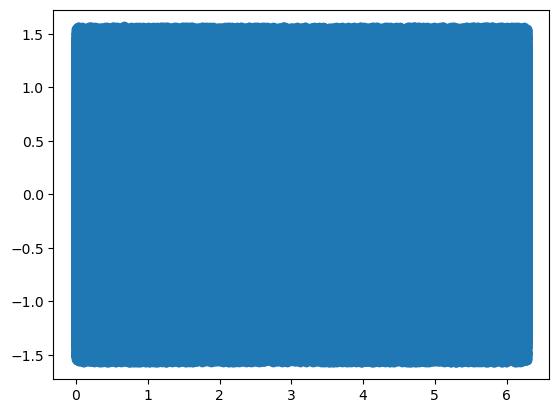

In [7]:
plt.scatter(ra_rad, dec_rad)

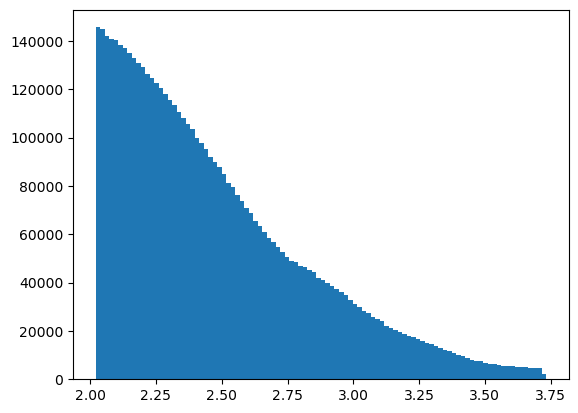

In [8]:
plt.hist(zq, bins=100);

In [9]:
# put everything into massive Nq x Nz arrays
sum_w_list = [np.array(dataset[ipix]['sum_w']) for ipix in range(nfiles)]
sum_w = np.concatenate(sum_w_list, axis=0)
mean_z_list = [np.array(dataset[ipix]['mean_z']) for ipix in range(nfiles)]
mean_z = np.concatenate(mean_z_list, axis=0)
mean_delta_list = [np.array(dataset[ipix]['mean_delta']) for ipix in range(nfiles)]
mean_delta = np.concatenate(mean_delta_list, axis=0)

Text(0.5, 0, '<z>')

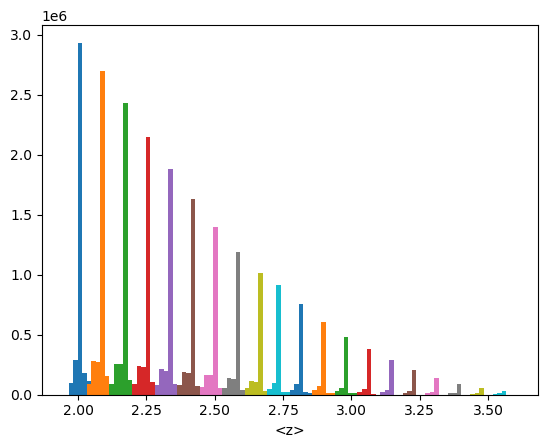

In [10]:
for iz in range(mean_z.shape[1]):
    plt.hist(mean_z[:,iz], bins=100, range=[1.95,3.6])
#plt.hist(mean_z[:,1], bins=100, range=[1.95,3.7])
#plt.hist(mean_z[:,2], bins=100, range=[1.95,3.7]);
plt.xlabel('<z>')

### Coadd into a single z-bin

In [11]:
sum_w_z=np.sum(sum_w, axis=1)
mean_delta_z=np.sum(sum_w*mean_delta, axis=1) / sum_w_z

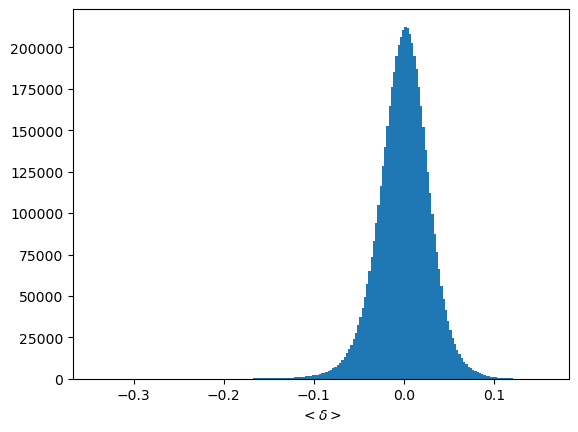

In [12]:
plt.hist(mean_delta_z, bins=200)
plt.xlabel(r'$<\delta>$');

### Create Healpix map

In [13]:
def catalog_to_healpix_map_rad(ra_rad, dec_rad, X, W, nside=128):
    """
    Create a Healpix map (RING ordering) where each pixel contains
    the weighted average of X for points falling into that pixel.

    Parameters
    ----------
    ra_deg : array-like
        Right Ascension in radians
    dec_deg : array-like
        Declination in radians
    X : array-like
        Scalar value for each catalog point
    W : array-like
        Weight for each catalog point
    nside : int
        Healpix nside parameter (default 512)

    Returns
    -------
    hp_map : numpy array
        Healpix map of weighted averages
    """

    ra_rad = np.asarray(ra_rad)
    dec_rad = np.asarray(dec_rad)
    X = np.asarray(X)
    W = np.asarray(W)

    npix = hp.nside2npix(nside)

    theta = np.pi/2 - dec_rad
    phi = ra_rad

    # Get pixel indices (RING ordering by default)
    pix = hp.ang2pix(nside, theta, phi)

    # Accumulate weighted sums
    weighted_sum = np.bincount(pix, weights=W * X, minlength=npix)
    weight_sum = np.bincount(pix, weights=W, minlength=npix)

    # Avoid division by zero
    hp_map = np.zeros(npix)
    mask = weight_sum > 0
    hp_map[mask] = weighted_sum[mask] / weight_sum[mask]

    return hp_map, weight_sum

In [14]:
hp_nside=128

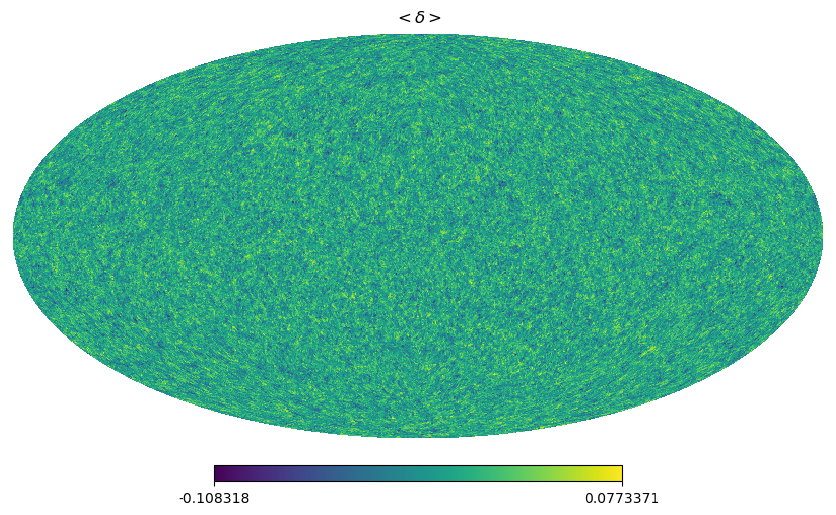

In [15]:
iz=1
delta_F_map, w_map = catalog_to_healpix_map_rad(ra_rad, dec_rad, X=mean_delta[:,iz], W=sum_w[:,iz], nside=hp_nside)
hp.mollview(delta_F_map, title=r'$<\delta>$')

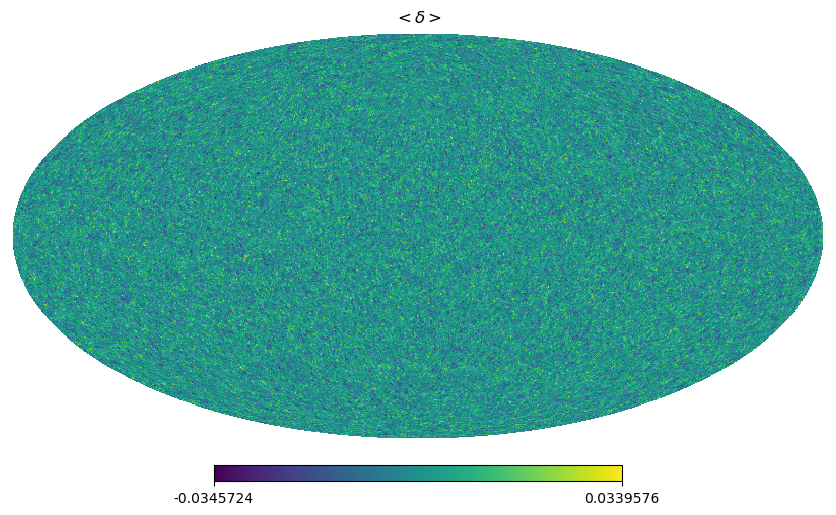

In [16]:
delta_F, w = catalog_to_healpix_map_rad(ra_rad, dec_rad, X=mean_delta_z, W=sum_w_z, nside=hp_nside)
hp.mollview(delta_F, title=r'$<\delta>$')

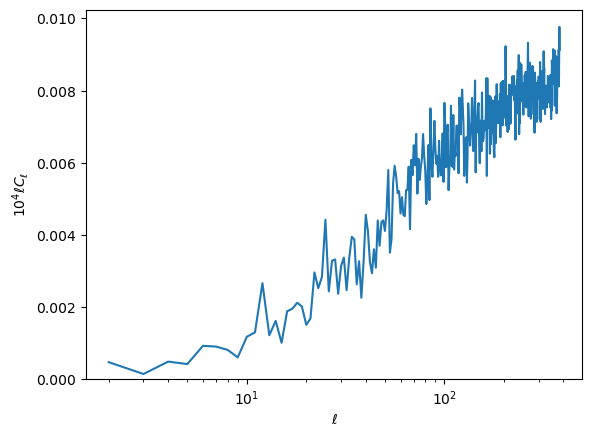

In [17]:
cl_FF = hp.anafast(delta_F)
ell = np.arange(len(cl_FF))

plt.semilogx(ell[2:], 1e4*ell[2:]*cl_FF[2:])
plt.xlabel(r'$\ell$')
plt.ylabel(r'$10^4 \ell C_\ell$')
plt.ylim(bottom=0)
plt.show()

### Read also the CMB kappa map

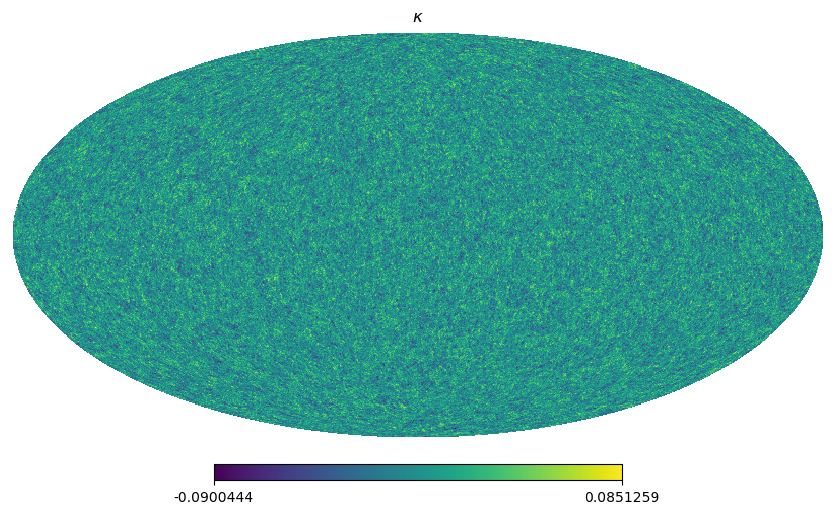

In [18]:
box_dir='/global/cfs/cdirs/desicollab/users/lauracdp/cmb_lensing_box/test_box-0/results'
m_k = hp.read_map(box_dir+'/out_kappa_z000.fits')
hp.mollview(m_k, title=r'$\kappa$')

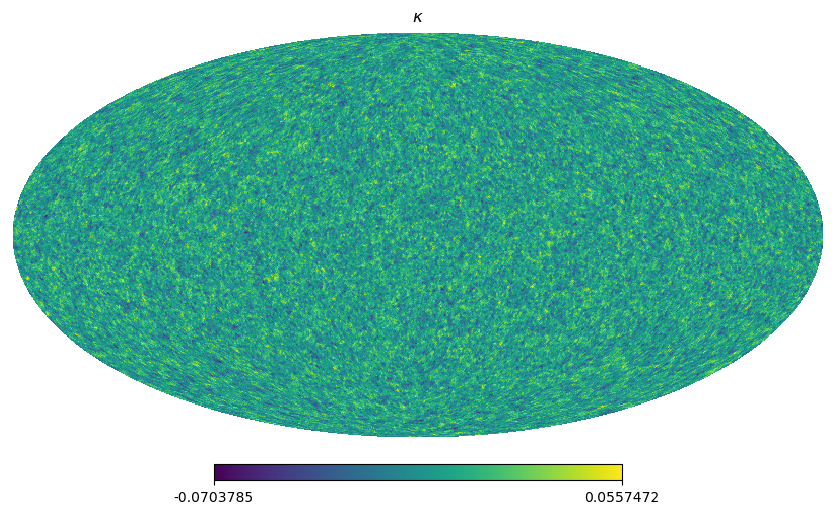

In [19]:
# try to get a lower resolution version of the map
m_k_lr = hp.ud_grade(m_k, nside_out=hp_nside)
hp.mollview(m_k_lr, title=r'$\kappa$')

In [20]:
def compute_cls_and_variances(cmb_map, delta_F, lmax=None, bin_width=None):

    # Compute spectra
    cl_tt = hp.anafast(cmb_map, lmax=lmax)
    cl_FF = hp.anafast(delta_F, lmax=lmax)
    cl_tF = hp.anafast(cmb_map, delta_F, lmax=lmax)

    ell = np.arange(len(cl_tt))

    # Variances (full sky: fsky = 1)
    var_tt = 2.0 * cl_tt**2 / (2*ell + 1)
    var_FF = 2.0 * cl_FF**2 / (2*ell + 1)
    var_tF = (cl_tF**2 + cl_tt*cl_FF) / (2*ell + 1)

    # Optional binning
    if bin_width is not None:
        def bin_array(arr):
            nb = len(arr) // bin_width
            return np.array([
                np.mean(arr[i*bin_width:(i+1)*bin_width])
                for i in range(nb)
            ])
            
        # I'm being lazy here
        ell = bin_array(ell)
        cl_tt = bin_array(cl_tt)
        cl_FF = bin_array(cl_FF)
        cl_tF = bin_array(cl_tF)
        var_tt = bin_array(var_tt) / bin_width
        var_FF = bin_array(var_FF) / bin_width
        var_tF = bin_array(var_tF) / bin_width

    return ell, cl_tt, cl_FF, cl_tF, var_tt, var_FF, var_tF


In [21]:
ell, cl_kk, cl_FF, cl_kF, var_kk, var_FF, var_kF = compute_cls_and_variances(m_k_lr, delta_F, lmax=None, bin_width=16)

In [22]:
def plot_cls(ell, cl_tt, cl_gg, cl_tg,
             var_tt, var_gg, var_tg, savefig=None):

    # Remove monopole/dipole
    m = ell >= 2
    ell = ell[m]

    cl_tt = cl_tt[m]
    cl_gg = cl_gg[m]
    cl_tg = cl_tg[m]

    sigma_tt = np.sqrt(var_tt[m])
    sigma_gg = np.sqrt(var_gg[m])
    sigma_tg = np.sqrt(var_tg[m])

    # Convert to D_ell
    prefac = ell * (ell + 1) / (2*np.pi)

    Dl_tt = prefac * cl_tt
    Dl_gg = prefac * cl_gg
    Dl_tg = prefac * cl_tg

    err_tt = prefac * sigma_tt
    err_gg = prefac * sigma_gg
    err_tg = prefac * sigma_tg

    # --- Plot ---
    fig, ax = plt.subplots(3, 1, figsize=(7, 10), sharex=True)

    ax[0].errorbar(ell, Dl_tt, yerr=err_tt, fmt='o', ms=3)
    ax[0].set_ylabel(r'$D_\ell^{\kappa \kappa}$')
    ax[0].set_title('Angular Power Spectra')

    ax[1].errorbar(ell, Dl_gg, yerr=err_gg, fmt='o', ms=3)
    ax[1].set_ylabel(r'$D_\ell^{FF}$')

    ax[2].errorbar(ell, Dl_tg, yerr=err_tg, fmt='o', ms=3)
    ax[2].set_ylabel(r'$D_\ell^{\kappa F}$')
    ax[2].set_xlabel(r'$\ell$')

    plt.tight_layout()
    if savefig:
        plt.savefig(savefig)

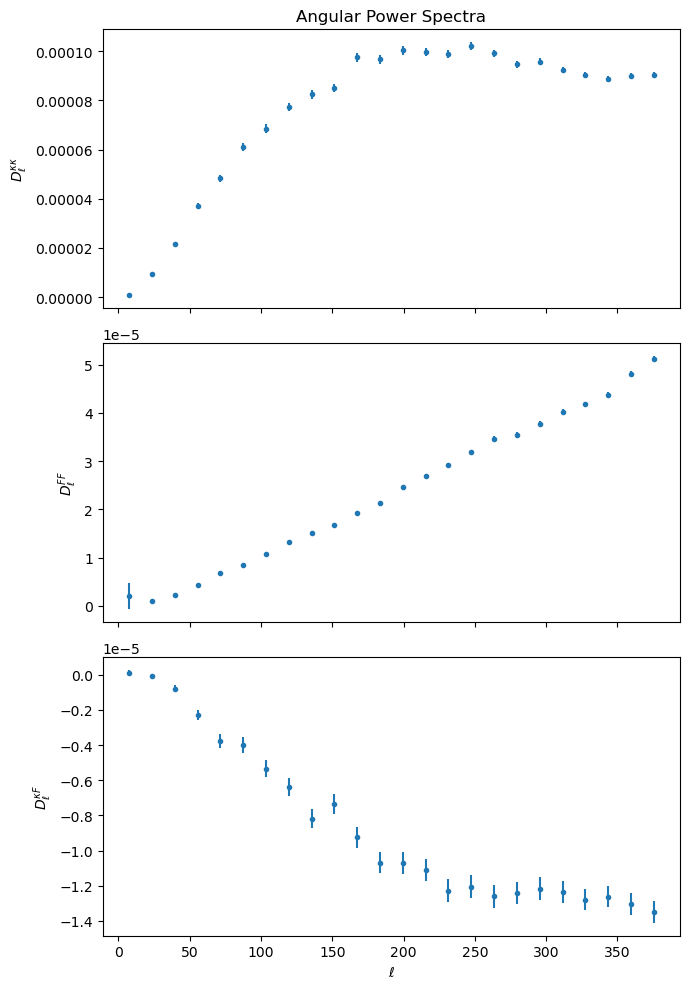

In [23]:
plot_cls(ell, cl_kk, cl_FF, cl_kF, var_kk, var_FF, var_kF, savefig='cmb_lya.png')

In [24]:
def plot_cross_cls(ell, cl_tg, var_tg, label):

    # Remove monopole/dipole
    m = ell >= 2
    ell = ell[m]
    cl_tg = cl_tg[m]
    sigma_tg = np.sqrt(var_tg[m])

    # Convert to D_ell
    prefac = ell * (ell + 1) / (2*np.pi)
    Dl_tg = prefac * cl_tg
    err_tg = prefac * sigma_tg

    plt.errorbar(ell, Dl_tg, yerr=err_tg, fmt='o', ms=3, label=label)

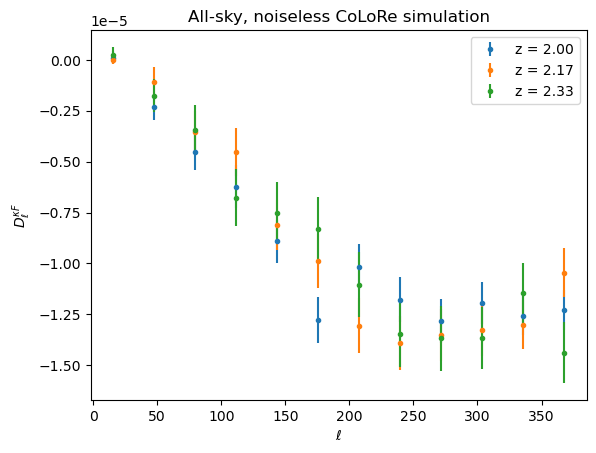

In [25]:
z=np.average(mean_z, axis=0, weights=sum_w)
Nz=len(z)
for iz in [0, 2, 4]:
#for iz in range(Nz):
    delta_F, w_map = catalog_to_healpix_map_rad(ra_rad, dec_rad, X=mean_delta[:,iz], W=sum_w[:,iz], nside=hp_nside)
    ell, cl_kk, cl_FF, cl_kF, var_kk, var_FF, var_kF = compute_cls_and_variances(m_k_lr, delta_F, lmax=None, bin_width=32)
    plot_cross_cls(ell, cl_kF, var_kF, label='z = {:.2f}'.format(z[iz]))
plt.legend()
plt.ylabel(r'$D_\ell^{\kappa F}$')
plt.xlabel(r'$\ell$')
plt.title('All-sky, noiseless CoLoRe simulation')
plt.savefig('cmb_lya_z.png')